# Exploratory Data Analysis (EDA)

This notebook explores the STEG Fraud Detection dataset to identify patterns related to electricity and gas consumption fraud.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

## Load Datasets

In [2]:
client_train = pd.read_csv('../data/raw/client_train.csv')
invoice_train = pd.read_csv('../data/raw/invoice_train.csv', low_memory=False)

print(f"Client Train Shape: {client_train.shape}")
print(f"Invoice Train Shape: {invoice_train.shape}")

Client Train Shape: (135493, 6)
Invoice Train Shape: (4476749, 16)


## 1. Client Data Exploration

In [3]:
client_train.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


### Target Distribution

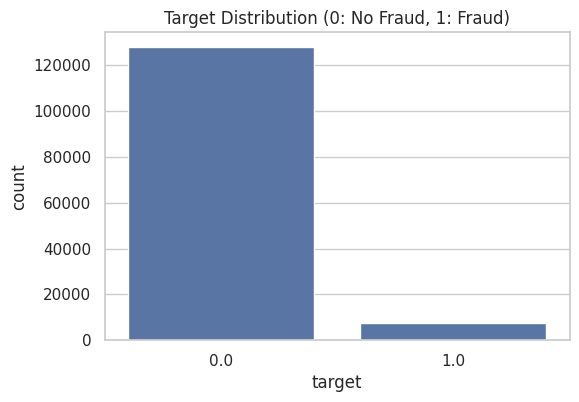

Target Proportions:
target
0.0    0.944159
1.0    0.055841
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=client_train)
plt.title('Target Distribution (0: No Fraud, 1: Fraud)')
plt.show()

print("Target Proportions:")
print(client_train['target'].value_counts(normalize=True))

### Client Categorical Features

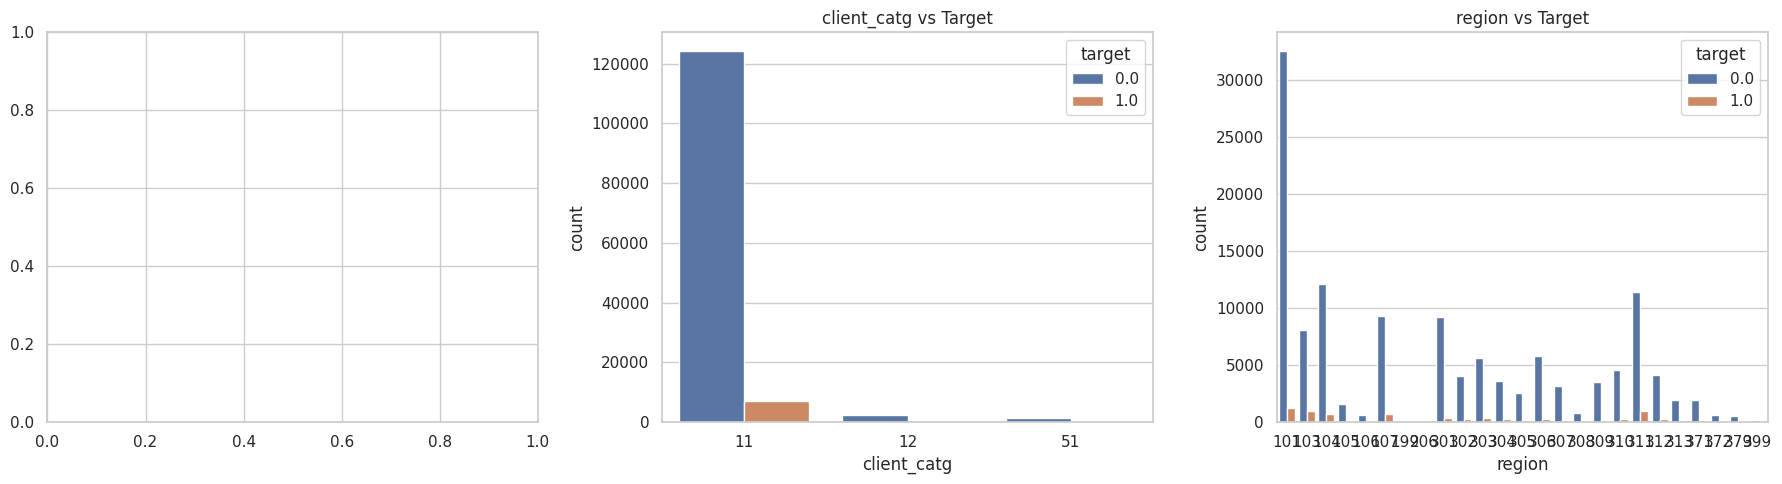

In [5]:
cat_cols = ['district', 'client_catg', 'region']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(cat_cols):
    if col in client_train.columns:
        sns.countplot(x=col, hue='target', data=client_train, ax=axes[i])
        axes[i].set_title(f'{col} vs Target')
plt.tight_layout()
plt.show()

## 2. Invoice Data Exploration

In [6]:
invoice_train.head()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC


### Consumption Levels

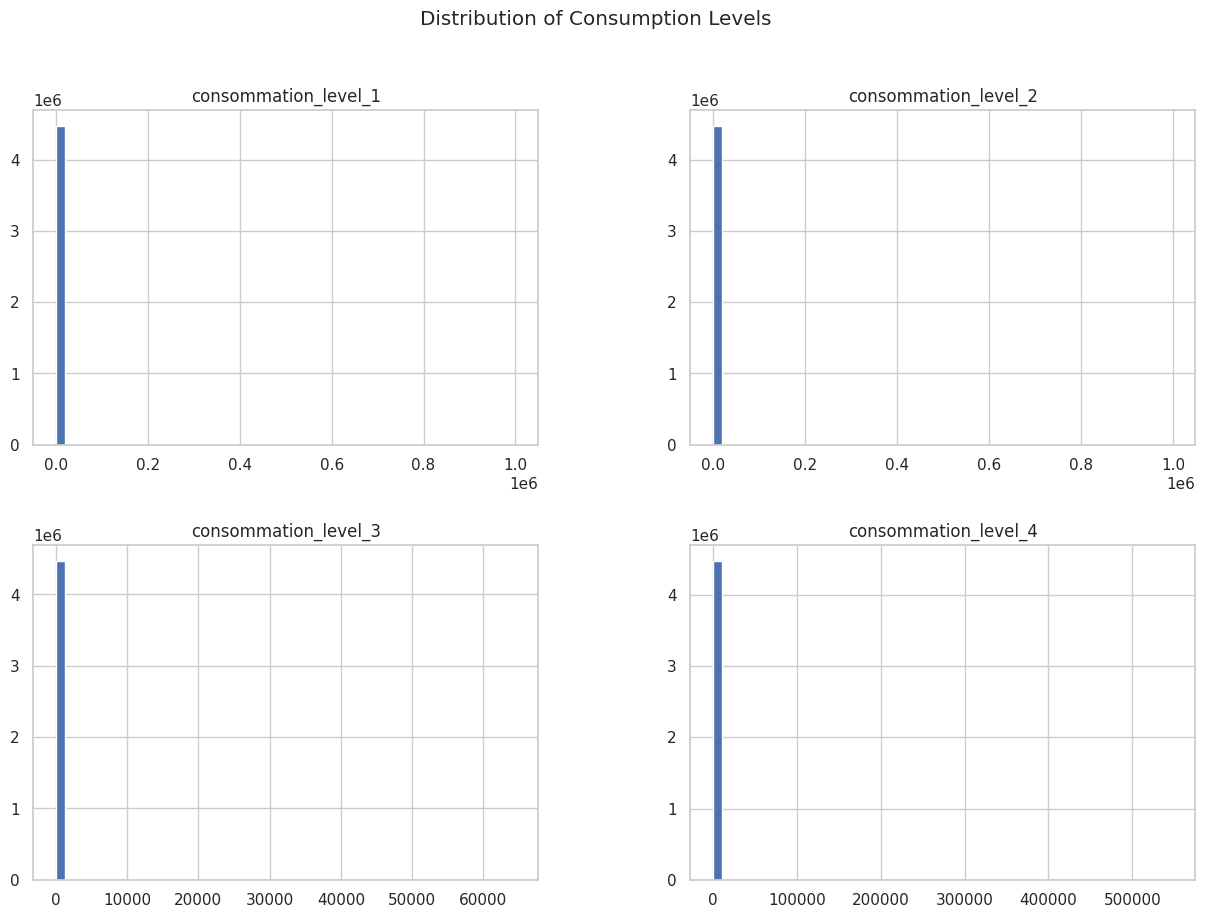

In [7]:
cons_cols = ['consommation_level_1', 'consommation_level_2', 'consommation_level_3', 'consommation_level_4']
invoice_train[cons_cols].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Consumption Levels')
plt.show()

## 3. Merging and Combined Analysis

In [8]:
# Aggregating invoice data per client to merge with client data
invoice_agg = invoice_train.groupby('client_id').agg({
    'consommation_level_1': ['mean', 'max', 'sum'],
    'invoice_date': 'count'
}).reset_index()

invoice_agg.columns = ['_'.join(col).strip('_') for col in invoice_agg.columns.values]

train_full = pd.merge(client_train, invoice_agg, on='client_id', how='left')
train_full.head()

,disrict,client_id,client_catg,region,creation_date,target,consommation_level_1_mean,consommation_level_1_max,consommation_level_1_sum,invoice_date_count
0,60,train_Client_0,11,101,31/12/1994,0.0,352.400000,1200,12334,35
1,69,train_Client_1,11,107,29/05/2002,0.0,557.540541,1207,20629,37
2,62,train_Client_10,11,301,13/03/1986,0.0,798.611111,2400,14375,18
3,69,train_Client_100,11,105,11/07/1996,0.0,1.200000,15,24,20
4,62,train_Client_1000,11,303,14/10/2014,0.0,663.714286,800,9292,14


### Correlation Heatmap

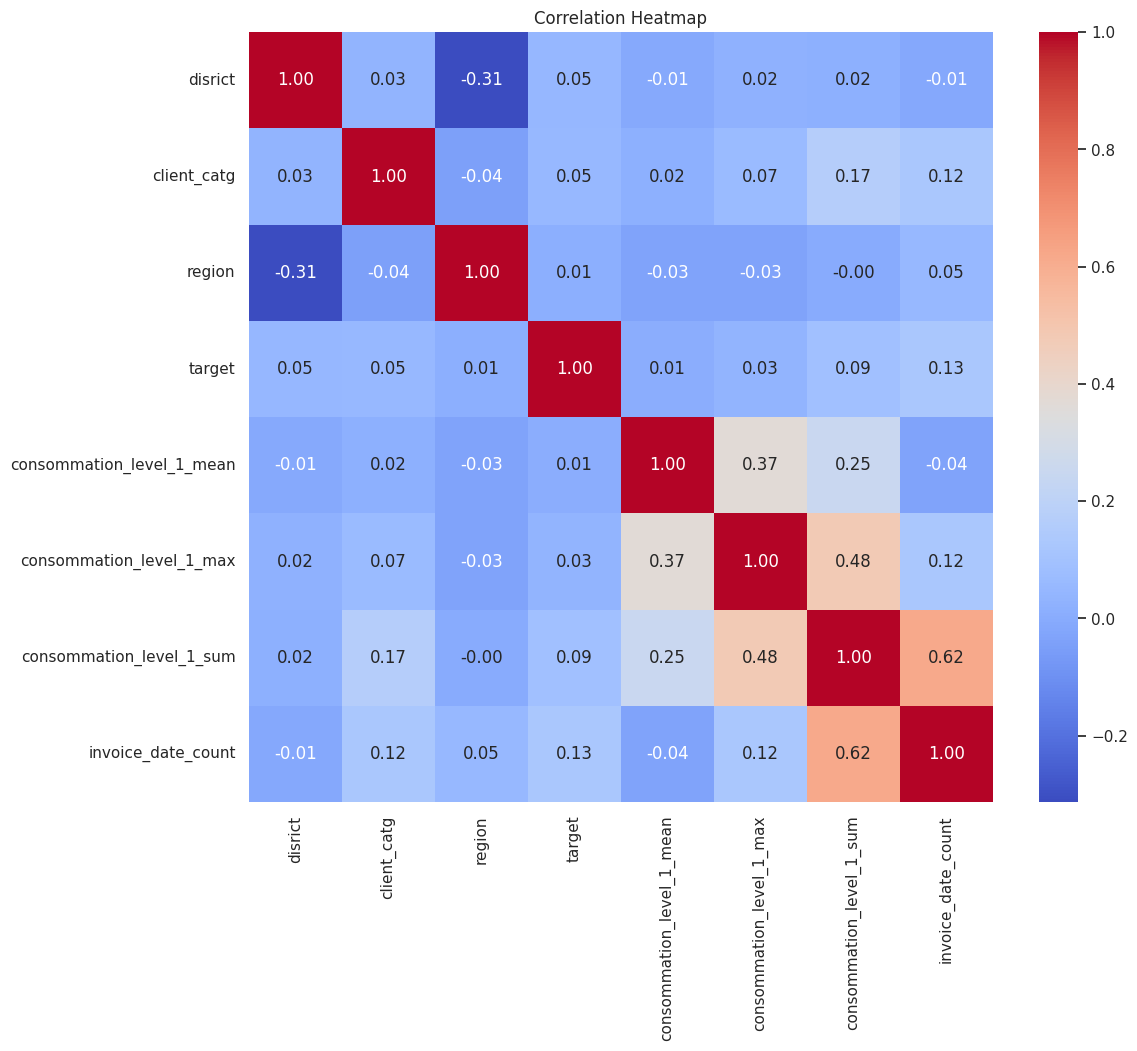

In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(train_full.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 4. Summary of Insights and Recommendations

Based on the preliminary exploration, here are the key insights and recommended strategies for modeling:

### 1. Severe Class Imbalance
- **Observation:** Approximately 5.6% of clients are labeled as fraudulent.
- **Impact:** Accuracy is not a reliable metric. We must focus on **PR-AUC (Precision-Recall AUC)**, F1-Score, and Recall.
- **Recommendation:** Use techniques like **class weights** (available in scikit-learn), during the training phase.

### 2. Temporal Features
- **Observation:** Each client has a long history of invoices (up to 4.47 million total).
- **Insight:** The frequency of invoices (`invoice_date_count`) and the length of the relationship (`days_since_creation`) are likely correlated with fraud potential.
- **Recommendation:** Generate more temporal features such as "average invoices per year" or "time between first and last invoice."

### 3. Consumption Patterns
- **Observation:** Most consumption is in `level_1`, but outliers in `level_2`, `level_3`, and `level_4` exist.
- **Insight:** Fraud often involves abnormal consumption shifts. Aggregates like `mean`, `max`, and `std` of these levels are critical indicators.
- **Recommendation:** Create ratios between consumption levels (e.g., `level_2 / level_1`) to capture unusual usage distributions.

### 4. Categorical Predictors
- **Observation:** Features like `district`, `client_catg`, and `region` show non-uniform fraud distributions.
- **Recommendation:** Ensure these are correctly encoded (e.g., One-Hot Encoding) for non-tree models, or handled natively for tree-based models like XGBoost/CatBoost.

### 5. Data Pipeline Recommendation
- Standardizing features is essential for models like SVM and KNN, which we have already implemented in `preprocess.py`. For Tree models, it is less critical but good for consistency.